<a href="https://colab.research.google.com/github/KausTryx/Library-Occupancy-and-Student-Study-Patterns-in-UNI-campus/blob/main/Library_Study_DMA_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
from google.colab import files
uploaded = files.upload()

Saving Library_data_DMA_stage2_input.csv to Library_data_DMA_stage2_input.csv


STAGE 1 - ⁠Data cleaning and preprocessing

In [6]:
#importing all libraries and loading data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("Library_data_DMA_stage2_input.csv")

# Create a backup of original data
df_original = df.copy()

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (128, 17)


,Response_ID,Q1_Year_of_study,Q2_Branch,Q3_Library_use_frequency,Q4_Preferred_study_location,Q5_Preferred_library_study_time,Q6_Typical_library_visit_duration,Q7_Main_reason_for_library_use,Q8_Library_study_days_per_week,Q9_Perceived_crowding,Q10_Difficulty_finding_seat,Q11_Period_library_most_crowded,Q12_Crowding_effect_on_concentration,Q13_Library_use_change_during_exams,Q14_Seat_availability_satisfaction_1_to_5,Q15_Overall_study_environment_rating_1_to_5,Q16_Suggested_improvement
0,68,3rd Year,CIVIL,Daily or almost daily,Hostel room / residence,5 PM–8 PM,30 minutes–1 hour,Use computers or the internet,6–7 days,Extremely crowded,Sometimes,Evening,Slightly,Stays about the same,4,4,Please add clearer signs for quiet areas.
1,43,3rd Year,ICE,3–5 days per week,University library,5 PM–8 PM,30 minutes–1 hour,Use computers or the internet,2–3 days,Slightly crowded,Often,Evening,Slightly,Increases slightly,3,3,A quieter space for online classes would be us...
2,54,1st Year,IT,3–5 days per week,University library,5 PM–8 PM,2–4 hours,Use computers or the internet,4–5 days,Crowded,Sometimes,"During exam periods, regardless of time",Slightly,Increases slightly,4,4,Provide easier access to digital journals.
3,113,2nd Year,CIVIL,Daily or almost daily,University library,5 PM–8 PM,1–2 hours,Personal study or work tasks,4–5 days,Moderately occupied,Rarely,Evening,Not sure,Increases significantly,3,4,Add a designated silent room.
4,121,2nd Year,DSE,Daily or almost daily,University library,"After 8 PM, if the library is open",1–2 hours,Access books and print references,4–5 days,Moderately occupied,Sometimes,"During exam periods, regardless of time",Slightly,Increases slightly,2,4,Make printing and scanning easier to access.


In [7]:
#checking data quality
# Check dataset information
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Check unique values in each column
for column in df.columns:
    print(f"\n{column}")
    print(df[column].value_counts(dropna=False))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128 entries, 0 to 127
Data columns (total 17 columns):
 #   Column                                       Non-Null Count  Dtype 
---  ------                                       --------------  ----- 
 0   Response_ID                                  128 non-null    int64 
 1   Q1_Year_of_study                             128 non-null    object
 2   Q2_Branch                                    128 non-null    object
 3   Q3_Library_use_frequency                     128 non-null    object
 4   Q4_Preferred_study_location                  128 non-null    object
 5   Q5_Preferred_library_study_time              128 non-null    object
 6   Q6_Typical_library_visit_duration            128 non-null    object
 7   Q7_Main_reason_for_library_use               128 non-null    object
 8   Q8_Library_study_days_per_week               128 non-null    object
 9   Q9_Perceived_crowding                        128 non-null    object
 10  Q10_Difficulty

In [8]:
#cleaning the dataset
# Clean column names
df.columns = df.columns.str.strip()

# Clean text values
for column in df.select_dtypes(include="object").columns:
    df[column] = df[column].str.strip()

# Replace empty strings with NaN
df.replace(r'^\s*$', np.nan, regex=True, inplace=True)

# Convert rating columns to numeric
rating_columns = [
    "Q14_Seat_availability_satisfaction_1_to_5",
    "Q15_Overall_study_environment_rating_1_to_5"
]

for column in rating_columns:
    df[column + "_numeric"] = pd.to_numeric(
        df[column], errors="coerce"
    )

print("Cleaning completed!")

Cleaning completed!


In [9]:
#handling missig values correctly
print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nNumeric rating summary:")
print(df[rating_columns[0] + "_numeric"].describe())
print(df[rating_columns[1] + "_numeric"].describe())

Missing values after cleaning:
Response_ID                                             0
Q1_Year_of_study                                        0
Q2_Branch                                               0
Q3_Library_use_frequency                                0
Q4_Preferred_study_location                             0
Q5_Preferred_library_study_time                         0
Q6_Typical_library_visit_duration                       0
Q7_Main_reason_for_library_use                          0
Q8_Library_study_days_per_week                          0
Q9_Perceived_crowding                                   0
Q10_Difficulty_finding_seat                             0
Q11_Period_library_most_crowded                         0
Q12_Crowding_effect_on_concentration                    0
Q13_Library_use_change_during_exams                     0
Q14_Seat_availability_satisfaction_1_to_5               0
Q15_Overall_study_environment_rating_1_to_5             0
Q16_Suggested_improvement                

In [10]:
#saving the cleaned dataset
df.to_csv("Library_data_cleaned.csv", index=False)

from google.colab import files
files.download("Library_data_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

STAGE 2 - Exploratory Data Analysis (EDA)

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Load cleaned dataset
df = pd.read_csv("Library_data_cleaned.csv")

print("EDA Started")
print("Total responses:", len(df))
print("Total columns:", len(df.columns))

EDA Started
Total responses: 128
Total columns: 19


In [12]:
#Understand the dataset
# Dataset overview
display(df.head())

# Dataset dimensions
print("Rows and Columns:", df.shape)

# Data types
print("\nData Types:")
print(df.dtypes)

# Summary of categorical variables
display(df.describe(include="object"))

,Response_ID,Q1_Year_of_study,Q2_Branch,Q3_Library_use_frequency,Q4_Preferred_study_location,Q5_Preferred_library_study_time,Q6_Typical_library_visit_duration,Q7_Main_reason_for_library_use,Q8_Library_study_days_per_week,Q9_Perceived_crowding,Q10_Difficulty_finding_seat,Q11_Period_library_most_crowded,Q12_Crowding_effect_on_concentration,Q13_Library_use_change_during_exams,Q14_Seat_availability_satisfaction_1_to_5,Q15_Overall_study_environment_rating_1_to_5,Q16_Suggested_improvement,Q14_Seat_availability_satisfaction_1_to_5_numeric,Q15_Overall_study_environment_rating_1_to_5_numeric
0,68,3rd Year,CIVIL,Daily or almost daily,Hostel room / residence,5 PM–8 PM,30 minutes–1 hour,Use computers or the internet,6–7 days,Extremely crowded,Sometimes,Evening,Slightly,Stays about the same,4,4,Please add clearer signs for quiet areas.,4.0,4.0
1,43,3rd Year,ICE,3–5 days per week,University library,5 PM–8 PM,30 minutes–1 hour,Use computers or the internet,2–3 days,Slightly crowded,Often,Evening,Slightly,Increases slightly,3,3,A quieter space for online classes would be us...,3.0,3.0
2,54,1st Year,IT,3–5 days per week,University library,5 PM–8 PM,2–4 hours,Use computers or the internet,4–5 days,Crowded,Sometimes,"During exam periods, regardless of time",Slightly,Increases slightly,4,4,Provide easier access to digital journals.,4.0,4.0
3,113,2nd Year,CIVIL,Daily or almost daily,University library,5 PM–8 PM,1–2 hours,Personal study or work tasks,4–5 days,Moderately occupied,Rarely,Evening,Not sure,Increases significantly,3,4,Add a designated silent room.,3.0,4.0
4,121,2nd Year,DSE,Daily or almost daily,University library,"After 8 PM, if the library is open",1–2 hours,Access books and print references,4–5 days,Moderately occupied,Sometimes,"During exam periods, regardless of time",Slightly,Increases slightly,2,4,Make printing and scanning easier to access.,2.0,4.0


Rows and Columns: (128, 19)

Data Types:
Response_ID                                              int64
Q1_Year_of_study                                        object
Q2_Branch                                               object
Q3_Library_use_frequency                                object
Q4_Preferred_study_location                             object
Q5_Preferred_library_study_time                         object
Q6_Typical_library_visit_duration                       object
Q7_Main_reason_for_library_use                          object
Q8_Library_study_days_per_week                          object
Q9_Perceived_crowding                                   object
Q10_Difficulty_finding_seat                             object
Q11_Period_library_most_crowded                         object
Q12_Crowding_effect_on_concentration                    object
Q13_Library_use_change_during_exams                     object
Q14_Seat_availability_satisfaction_1_to_5               object
Q15_Overall_st

,Q1_Year_of_study,Q2_Branch,Q3_Library_use_frequency,Q4_Preferred_study_location,Q5_Preferred_library_study_time,Q6_Typical_library_visit_duration,Q7_Main_reason_for_library_use,Q8_Library_study_days_per_week,Q9_Perceived_crowding,Q10_Difficulty_finding_seat,Q11_Period_library_most_crowded,Q12_Crowding_effect_on_concentration,Q13_Library_use_change_during_exams,Q14_Seat_availability_satisfaction_1_to_5,Q15_Overall_study_environment_rating_1_to_5,Q16_Suggested_improvement
count,128,128,128,128,128,128,128,128,128,128,128,128,128,128,128,115
unique,4,14,5,5,6,6,7,6,6,5,6,5,7,6,6,26
top,3rd Year,MNC,3–5 days per week,University library,5 PM–8 PM,1–2 hours,Study with fewer distractions,2–3 days,Crowded,Often,"During exam periods, regardless of time",Slightly,Increases significantly,4,3,Improve ventilation in the study rooms.
freq,64,14,51,77,55,49,33,44,44,50,55,49,38,38,38,7


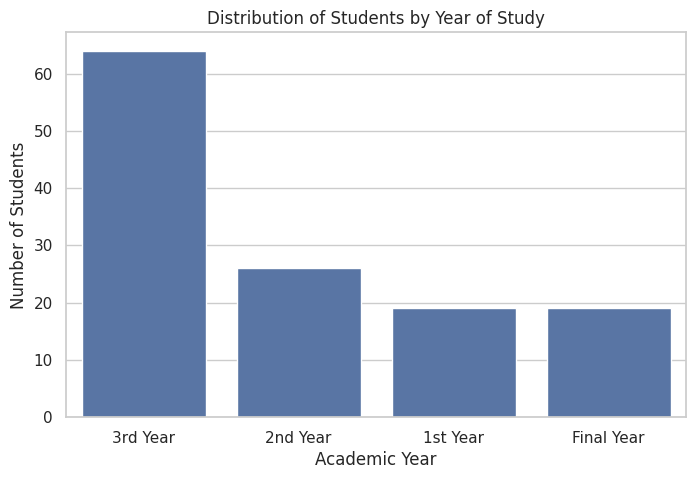

In [13]:
#Analyze student demographics
#year of their study
year_counts = df["Q1_Year_of_study"].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(x=year_counts.index, y=year_counts.values)

plt.title("Distribution of Students by Year of Study")
plt.xlabel("Academic Year")
plt.ylabel("Number of Students")
plt.show()

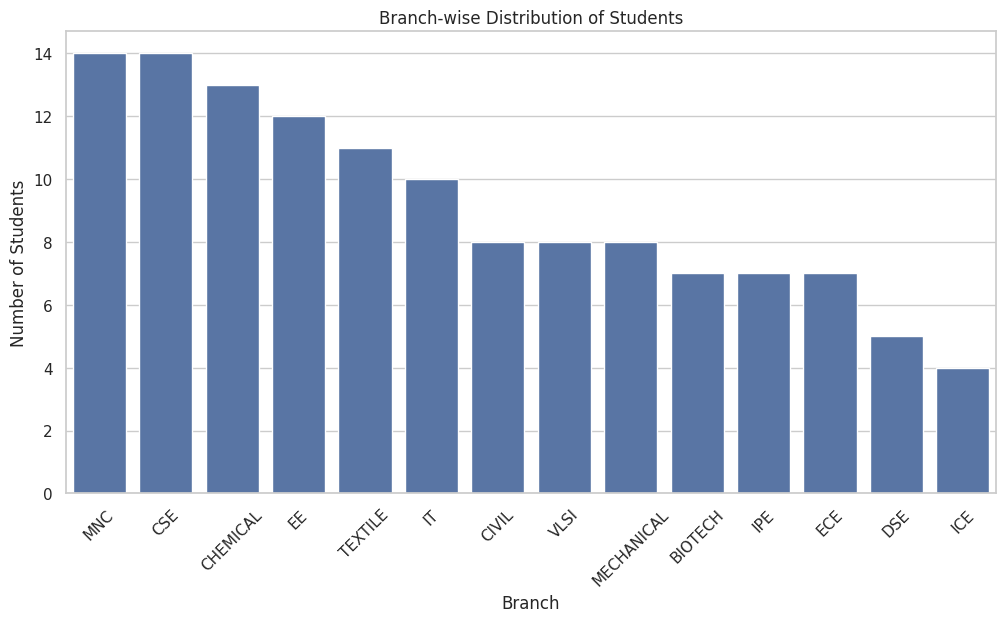

In [14]:
#Branch-wise distribution
branch_counts = df["Q2_Branch"].value_counts()

plt.figure(figsize=(12, 6))
sns.barplot(
    x=branch_counts.index,
    y=branch_counts.values
)

plt.title("Branch-wise Distribution of Students")
plt.xlabel("Branch")
plt.ylabel("Number of Students")
plt.xticks(rotation=45)
plt.show()

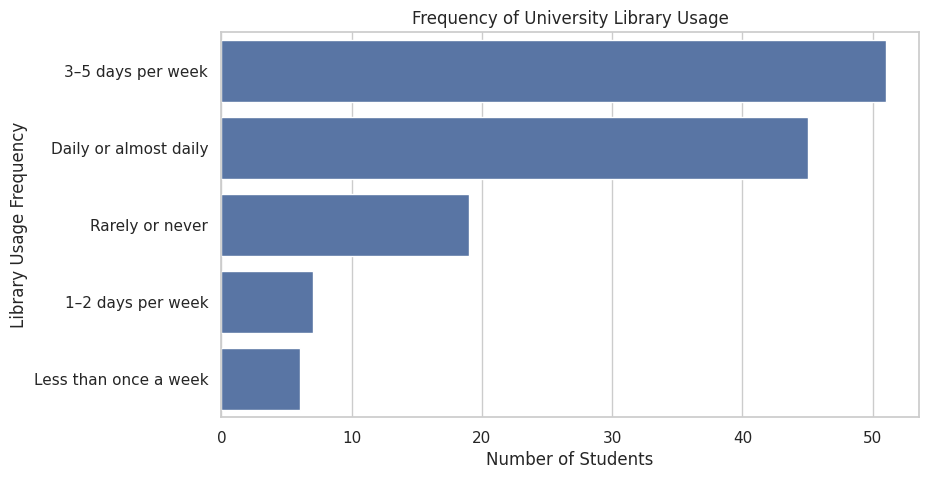

In [15]:
#Analyze library usage patterns
#How frequently do students use the library?
col = "Q3_Library_use_frequency"

counts = df[col].value_counts()

plt.figure(figsize=(9, 5))
sns.barplot(x=counts.values, y=counts.index)

plt.title("Frequency of University Library Usage")
plt.xlabel("Number of Students")
plt.ylabel("Library Usage Frequency")
plt.show()

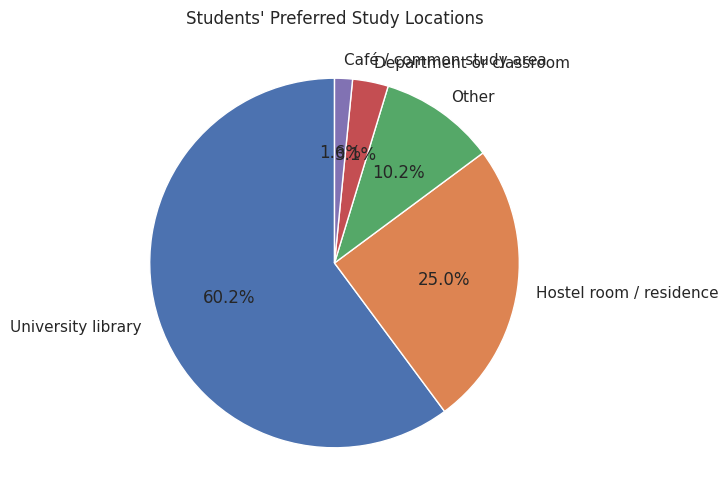

In [16]:
#Preferred study location
col = "Q4_Preferred_study_location"

counts = df[col].value_counts()

plt.figure(figsize=(8, 6))
plt.pie(
    counts.values,
    labels=counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Students' Preferred Study Locations")
plt.show()

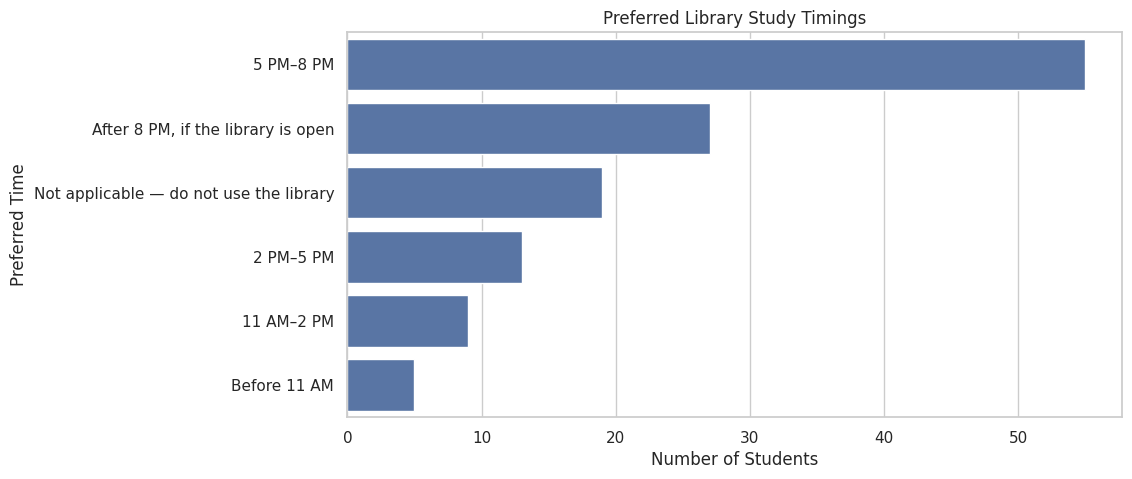

In [17]:
#Preferred library study time
col = "Q5_Preferred_library_study_time"

counts = df[col].value_counts()

plt.figure(figsize=(10, 5))
sns.barplot(x=counts.values, y=counts.index)

plt.title("Preferred Library Study Timings")
plt.xlabel("Number of Students")
plt.ylabel("Preferred Time")
plt.show()

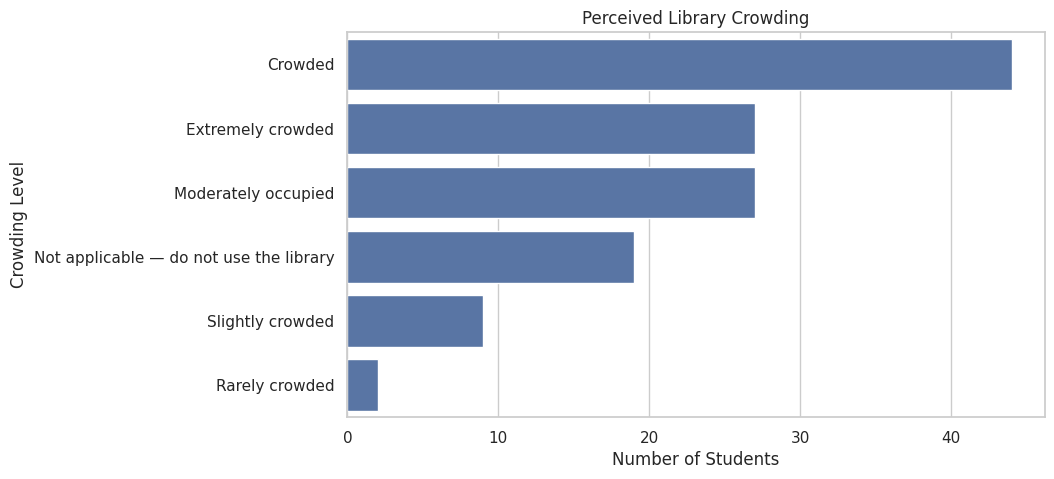

In [18]:
#Analyze library conditions
#Perceived library crowding
col = "Q9_Perceived_crowding"

counts = df[col].value_counts()

plt.figure(figsize=(9, 5))
sns.barplot(x=counts.values, y=counts.index)

plt.title("Perceived Library Crowding")
plt.xlabel("Number of Students")
plt.ylabel("Crowding Level")
plt.show()

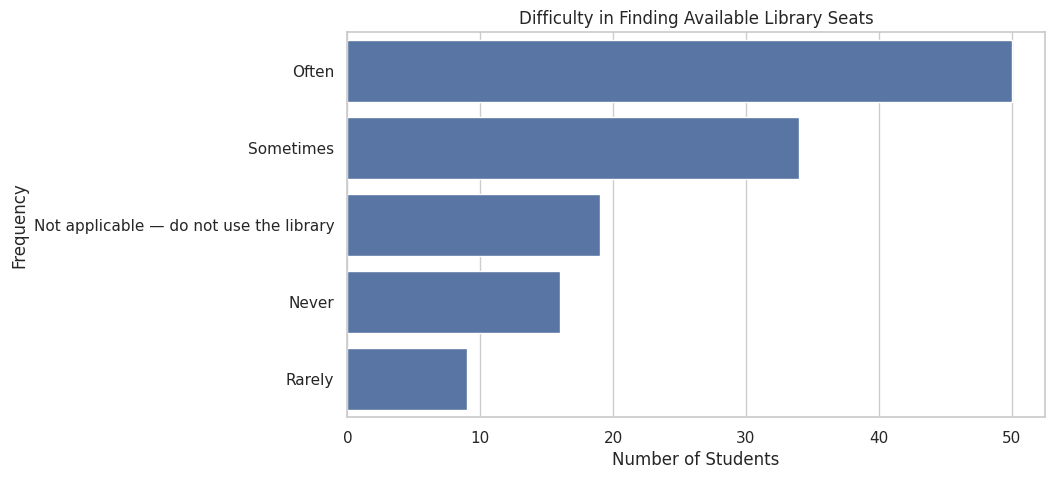

In [19]:
#Difficulty finding seats
col = "Q10_Difficulty_finding_seat"

counts = df[col].value_counts()

plt.figure(figsize=(9, 5))
sns.barplot(x=counts.values, y=counts.index)

plt.title("Difficulty in Finding Available Library Seats")
plt.xlabel("Number of Students")
plt.ylabel("Frequency")
plt.show()

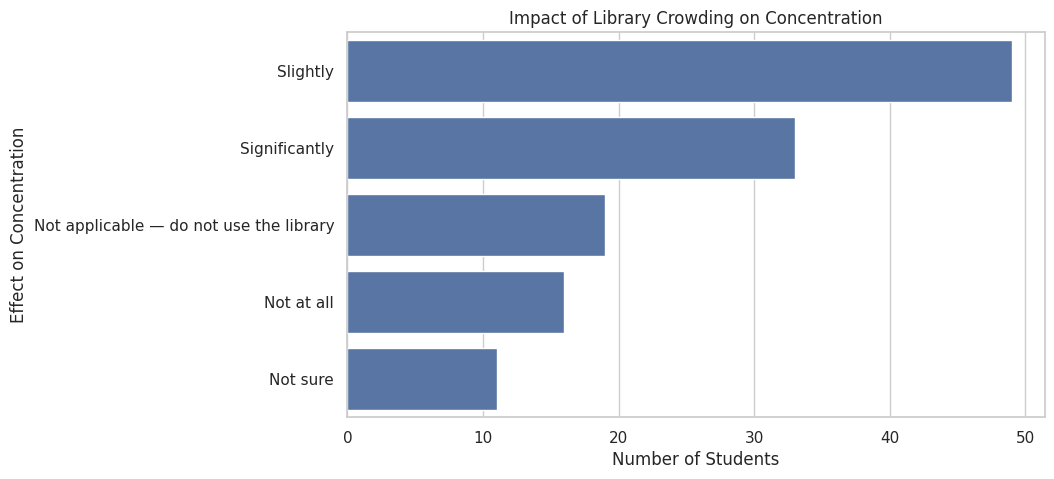

In [20]:
#Effect of crowding on concentration
col = "Q12_Crowding_effect_on_concentration"

counts = df[col].value_counts()

plt.figure(figsize=(9, 5))
sns.barplot(x=counts.values, y=counts.index)

plt.title("Impact of Library Crowding on Concentration")
plt.xlabel("Number of Students")
plt.ylabel("Effect on Concentration")
plt.show()

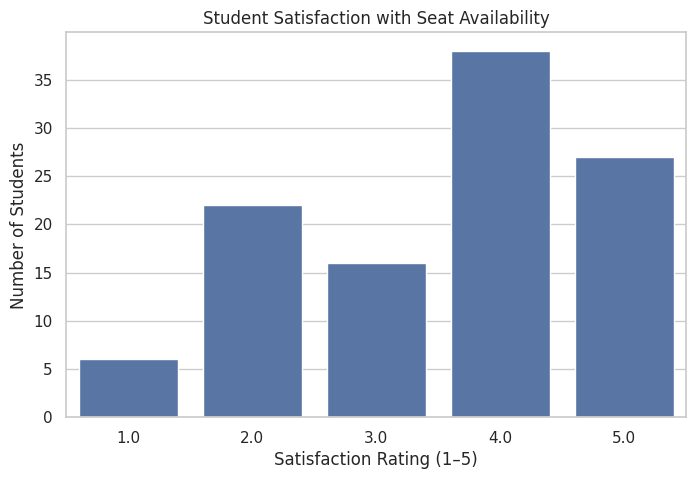

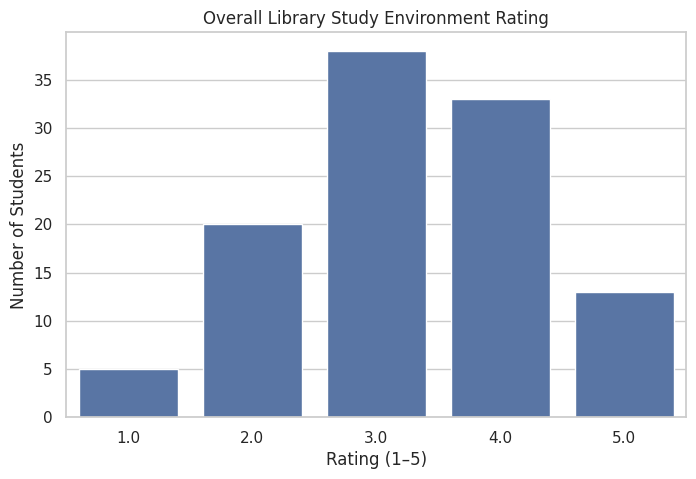

In [21]:
#Analyze student satisfaction
# Convert ratings to numeric values
df["Q14_numeric"] = pd.to_numeric(
    df["Q14_Seat_availability_satisfaction_1_to_5"],
    errors="coerce"
)

df["Q15_numeric"] = pd.to_numeric(
    df["Q15_Overall_study_environment_rating_1_to_5"],
    errors="coerce"
)

# Plot seat satisfaction
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Q14_numeric")

plt.title("Student Satisfaction with Seat Availability")
plt.xlabel("Satisfaction Rating (1–5)")
plt.ylabel("Number of Students")
plt.show()

# Plot overall environment rating
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Q15_numeric")

plt.title("Overall Library Study Environment Rating")
plt.xlabel("Rating (1–5)")
plt.ylabel("Number of Students")
plt.show()

In [22]:
#Generate a statistical summary
print("AVERAGE SEAT AVAILABILITY SATISFACTION:",
      df["Q14_numeric"].mean())

print("AVERAGE LIBRARY ENVIRONMENT RATING:",
      df["Q15_numeric"].mean())

print("\nMOST COMMON LIBRARY USAGE:")
print(df["Q3_Library_use_frequency"].mode()[0])

print("\nMOST COMMON STUDY LOCATION:")
print(df["Q4_Preferred_study_location"].mode()[0])

print("\nMOST COMMON STUDY TIME:")
print(df["Q5_Preferred_library_study_time"].mode()[0])

AVERAGE SEAT AVAILABILITY SATISFACTION: 3.532110091743119
AVERAGE LIBRARY ENVIRONMENT RATING: 3.2660550458715596

MOST COMMON LIBRARY USAGE:
3–5 days per week

MOST COMMON STUDY LOCATION:
University library

MOST COMMON STUDY TIME:
5 PM–8 PM


In [23]:
plt.savefig(
    "library_analysis.png",
    dpi=300,
    bbox_inches="tight"
)


<Figure size 640x480 with 0 Axes>

Stage 4 — Statistical Analysis

In [24]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

In [25]:
print(df.columns.tolist())

['Response_ID', 'Q1_Year_of_study', 'Q2_Branch', 'Q3_Library_use_frequency', 'Q4_Preferred_study_location', 'Q5_Preferred_library_study_time', 'Q6_Typical_library_visit_duration', 'Q7_Main_reason_for_library_use', 'Q8_Library_study_days_per_week', 'Q9_Perceived_crowding', 'Q10_Difficulty_finding_seat', 'Q11_Period_library_most_crowded', 'Q12_Crowding_effect_on_concentration', 'Q13_Library_use_change_during_exams', 'Q14_Seat_availability_satisfaction_1_to_5', 'Q15_Overall_study_environment_rating_1_to_5', 'Q16_Suggested_improvement', 'Q14_Seat_availability_satisfaction_1_to_5_numeric', 'Q15_Overall_study_environment_rating_1_to_5_numeric', 'Q14_numeric', 'Q15_numeric']


In [29]:
#Step 2 — Create a reusable statistical analysis function
def analyze_relationship(data, col1, col2):

    # Remove missing and not-applicable responses
    temp = data[[col1, col2]].copy()

    temp = temp.dropna()

    invalid_values = [
        "Not applicable",
        "Not applicable — do not use the library",
        "Do not use the library",
        "I do not use the library"
    ]

    for col in [col1, col2]:
        temp = temp[
            ~temp[col].astype(str).str.strip().isin(invalid_values)
        ]

    # Create cross-tabulation
    table = pd.crosstab(temp[col1], temp[col2])

    print("\nCROSS TABULATION")
    display(table)

    # Chi-square test
    chi2, p, dof, expected = chi2_contingency(table)

    # Calculate Cramer's V
    n = table.to_numpy().sum()
    r, k = table.shape

    cramers_v = np.sqrt(
        chi2 / (n * min(r - 1, k - 1))
    ) if n > 0 and min(r - 1, k - 1) > 0 else np.nan

    print("\nSTATISTICAL RESULTS")
    print("Chi-square statistic:", round(chi2, 4))
    print("P-value:", round(p, 5))
    print("Degrees of freedom:", dof)
    print("Cramer's V:", round(cramers_v, 4))

    print(
        "Expected cells below 5:",
        round((expected < 5).mean() * 100, 2), "%"
    )

    if p < 0.05:
        print("Interpretation: Evidence of an association.")
    else:
        print("Interpretation: Insufficient evidence of an association.")

    return table, chi2, p, cramers_v

In [30]:
#Step 3 — Perform our first statistical test
result_1 = analyze_relationship(
    df,
    "Q1_Year_of_study",
    "Q3_Library_use_frequency"
)


CROSS TABULATION


Q3_Library_use_frequency,1–2 days per week,3–5 days per week,Daily or almost daily,Less than once a week,Rarely or never
Q1_Year_of_study,,,,,
1st Year,1,7,3,3,5
2nd Year,3,9,12,0,2
3rd Year,3,27,23,2,9
Final Year,0,8,7,1,3



STATISTICAL RESULTS
Chi-square statistic: 15.325
P-value: 0.22414
Degrees of freedom: 12
Cramer's V: 0.1998
Expected cells below 5: 55.0 %
Interpretation: Insufficient evidence of an association.


In [31]:
#Step 4 — Analyze library crowding
#Research question 2: Is perceived crowding associated with difficulty finding seats?
result_2 = analyze_relationship(
    df,
    "Q9_Perceived_crowding",
    "Q10_Difficulty_finding_seat"
)


CROSS TABULATION


Q10_Difficulty_finding_seat,Never,Often,Rarely,Sometimes
Q9_Perceived_crowding,,,,
Crowded,5,26,3,10
Extremely crowded,4,13,2,8
Moderately occupied,6,6,2,13
Rarely crowded,0,0,1,1
Slightly crowded,1,5,1,2



STATISTICAL RESULTS
Chi-square statistic: 16.2946
P-value: 0.17811
Degrees of freedom: 12
Cramer's V: 0.2232
Expected cells below 5: 65.0 %
Interpretation: Insufficient evidence of an association.


In [33]:
#Research question 3: Does crowding relate to concentration?
result_3 = analyze_relationship(
    df,
    "Q9_Perceived_crowding",
    "Q12_Crowding_effect_on_concentration"
)


CROSS TABULATION


Q12_Crowding_effect_on_concentration,Not at all,Not sure,Significantly,Slightly
Q9_Perceived_crowding,,,,
Crowded,6,6,14,18
Extremely crowded,4,3,9,11
Moderately occupied,2,2,9,14
Rarely crowded,1,0,1,0
Slightly crowded,3,0,0,6



STATISTICAL RESULTS
Chi-square statistic: 12.296
P-value: 0.42221
Degrees of freedom: 12
Cramer's V: 0.1939
Expected cells below 5: 65.0 %
Interpretation: Insufficient evidence of an association.


In [34]:
#Step 5 — Analyze student satisfaction
from scipy.stats import spearmanr

q14 = pd.to_numeric(df["Q14_numeric"], errors="coerce")
q15 = pd.to_numeric(df["Q15_numeric"], errors="coerce")

valid = pd.DataFrame({
    "Seat_Satisfaction": q14,
    "Environment_Rating": q15
}).dropna()

rho, p_value = spearmanr(
    valid["Seat_Satisfaction"],
    valid["Environment_Rating"]
)

print("Spearman Correlation:", round(rho, 4))
print("P-value:", round(p_value, 5))

if p_value < 0.05:
    print("There is evidence of a statistically significant relationship.")
else:
    print("There is insufficient evidence of a statistically significant relationship.")

Spearman Correlation: -0.0836
P-value: 0.38731
There is insufficient evidence of a statistically significant relationship.


Stage 5 — Data Mining and Machine Learning

In [35]:
#4. Prepare the clustering dataset
# Display relevant question columns and their values

for col in df.columns:
    if col.startswith(("Q3", "Q6", "Q8", "Q9", "Q10", "Q14", "Q15")):
        print("\n", col)
        print(df[col].value_counts(dropna=False))


 Q3_Library_use_frequency
Q3_Library_use_frequency
3–5 days per week        51
Daily or almost daily    45
Rarely or never          19
1–2 days per week         7
Less than once a week     6
Name: count, dtype: int64

 Q6_Typical_library_visit_duration
Q6_Typical_library_visit_duration
1–2 hours                                  49
2–4 hours                                  33
30 minutes–1 hour                          20
Not applicable — do not use the library    19
Less than 30 minutes                        5
More than 4 hours                           2
Name: count, dtype: int64

 Q8_Library_study_days_per_week
Q8_Library_study_days_per_week
2–3 days                          44
4–5 days                          32
6–7 days                          20
Never / do not use the library    19
1 day                              7
Less than once a week              6
Name: count, dtype: int64

 Q9_Perceived_crowding
Q9_Perceived_crowding
Crowded                                    44
Extrem

In [37]:
#Next, create ordinal mappings. These mappings assign increasing scores to answers that have a natural order.
# Define ordered response mappings

frequency_map = {
    "Rarely or never": 0,
    "Less than once a week": 1,
    "1–2 days per week": 2,
    "3–5 days per week": 3,
    "Daily or almost daily": 4
}

duration_map = {
    "Less than 30 minutes": 0,
    "30 minutes–1 hour": 1,
    "1–2 hours": 2,
    "2–4 hours": 3,
    "More than 4 hours": 4
}

days_map = {
    "0 days": 0,
    "1 day": 1,
    "2–3 days": 2,
    "4–5 days": 3,
    "6–7 days": 4
}

In [38]:
crowding_map = {
    "Very empty": 0,
    "Somewhat empty": 1,
    "Moderately occupied": 2,
    "Crowded": 3,
    "Extremely crowded": 4
}

seat_difficulty_map = {
    "Never": 0,
    "Rarely": 1,
    "Sometimes": 2,
    "Often": 3,
    "Almost always": 4
}


In [41]:
#5. Create the numerical dataset
# Prepare selected features

features = pd.DataFrame()

features["Frequency"] = df["Q3_Library_use_frequency"].map(frequency_map)

features["Duration"] = df["Q6_Visit_duration"].map(duration_map)

features["Weekly_Days"] = df["Q8_Library_study_days"].map(days_map)

features["Crowding"] = df["Q9_Perceived_crowding"].map(crowding_map)

features["Seat_Difficulty"] = df["Q10_Difficulty_finding_seat"].map(seat_difficulty_map)

features["Seat_Satisfaction"] = pd.to_numeric(
    df["Q14_numeric"], errors="coerce"
)

features["Environment_Rating"] = pd.to_numeric(
    df["Q15_numeric"], errors="coerce"
)

# Remove records with missing or not-applicable feature values
features = features.dropna()

print("Prepared clustering dataset:", features.shape)

display(features.head())

KeyError: 'Q6_Visit_duration'

In [42]:
for col in df.columns:
    print(col)


Response_ID
Q1_Year_of_study
Q2_Branch
Q3_Library_use_frequency
Q4_Preferred_study_location
Q5_Preferred_library_study_time
Q6_Typical_library_visit_duration
Q7_Main_reason_for_library_use
Q8_Library_study_days_per_week
Q9_Perceived_crowding
Q10_Difficulty_finding_seat
Q11_Period_library_most_crowded
Q12_Crowding_effect_on_concentration
Q13_Library_use_change_during_exams
Q14_Seat_availability_satisfaction_1_to_5
Q15_Overall_study_environment_rating_1_to_5
Q16_Suggested_improvement
Q14_Seat_availability_satisfaction_1_to_5_numeric
Q15_Overall_study_environment_rating_1_to_5_numeric
Q14_numeric
Q15_numeric


In [43]:
for col in df.columns:
    if "Q6" in col:
        print("Column:", col)
        print(df[col].value_counts(dropna=False))


Column: Q6_Typical_library_visit_duration
Q6_Typical_library_visit_duration
1–2 hours                                  49
2–4 hours                                  33
30 minutes–1 hour                          20
Not applicable — do not use the library    19
Less than 30 minutes                        5
More than 4 hours                           2
Name: count, dtype: int64


In [45]:
# Prepare selected features

features = pd.DataFrame()

features["Frequency"] = df["Q3_Library_use_frequency"].map(frequency_map)

features["Duration"] = df["Q6_Typical_library_visit_duration"].map(duration_map)

features["Weekly_Days"] = df["Q8_Library_study_days_per_week"].map(days_map)

features["Crowding"] = df["Q9_Perceived_crowding"].map(crowding_map)

features["Seat_Difficulty"] = df["Q10_Difficulty_finding_seat"].map(seat_difficulty_map)

features["Seat_Satisfaction"] = pd.to_numeric(
    df["Q14_numeric"], errors="coerce"
)

features["Environment_Rating"] = pd.to_numeric(
    df["Q15_numeric"], errors="coerce"
)

# Remove records with missing or not-applicable feature values
features = features.dropna()

print("Prepared clustering dataset:", features.shape)

display(features.head())

Prepared clustering dataset: (92, 7)


,Frequency,Duration,Weekly_Days,Crowding,Seat_Difficulty,Seat_Satisfaction,Environment_Rating
0,4,1.0,4.0,4.0,2.0,4.0,4.0
2,3,3.0,3.0,3.0,2.0,4.0,4.0
3,4,2.0,3.0,2.0,1.0,3.0,4.0
4,4,2.0,3.0,2.0,2.0,2.0,4.0
5,4,3.0,3.0,3.0,3.0,4.0,3.0


In [46]:
#6. Standardize the data
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(features)

print("Standardization completed!")

Standardization completed!


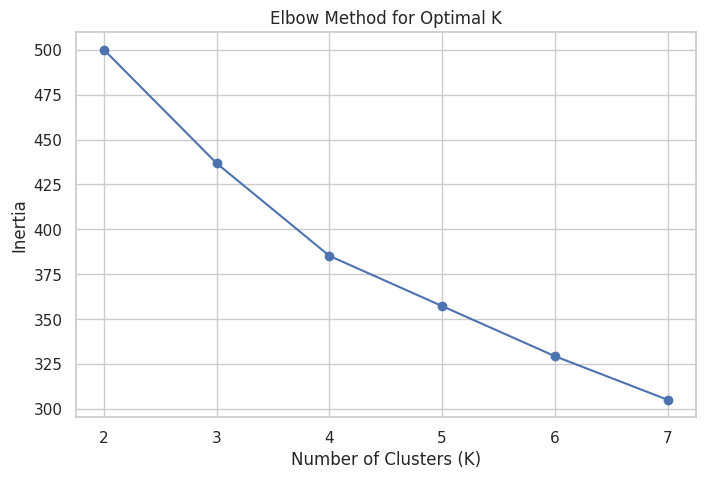

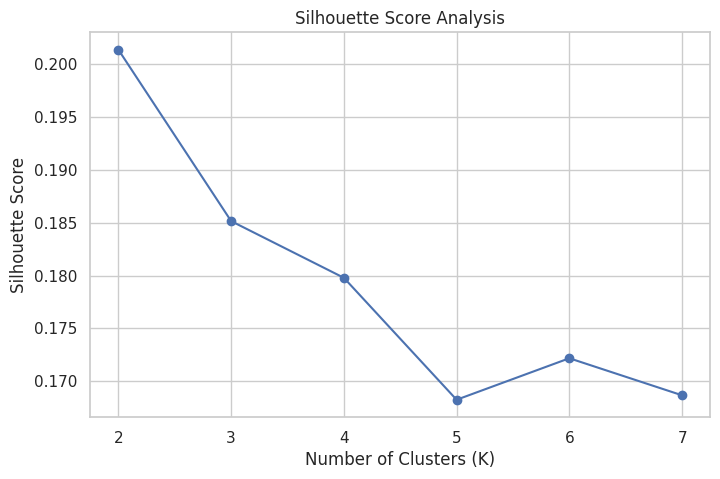

In [47]:
#7. Find the optimal number of clusters
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia_values = []
silhouette_values = []

K_range = range(2, 8)

for k in K_range:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inertia_values.append(model.inertia_)
    silhouette_values.append(
        silhouette_score(X_scaled, labels)
    )

# Elbow plot
plt.figure(figsize=(8, 5))
plt.plot(list(K_range), inertia_values, marker="o")

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.show()

# Silhouette plot
plt.figure(figsize=(8, 5))
plt.plot(list(K_range), silhouette_values, marker="o")

plt.title("Silhouette Score Analysis")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.show()

In [48]:
#8. Apply K-Means clustering
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

features["Cluster"] = kmeans.fit_predict(X_scaled)

print("Clustering completed!")

display(features.head())

Clustering completed!


,Frequency,Duration,Weekly_Days,Crowding,Seat_Difficulty,Seat_Satisfaction,Environment_Rating,Cluster
0,4,1.0,4.0,4.0,2.0,4.0,4.0,0
2,3,3.0,3.0,3.0,2.0,4.0,4.0,1
3,4,2.0,3.0,2.0,1.0,3.0,4.0,0
4,4,2.0,3.0,2.0,2.0,2.0,4.0,0
5,4,3.0,3.0,3.0,3.0,4.0,3.0,0


In [49]:
cluster_summary = features.groupby("Cluster").mean().round(2)

display(cluster_summary)


,Frequency,Duration,Weekly_Days,Crowding,Seat_Difficulty,Seat_Satisfaction,Environment_Rating
Cluster,,,,,,,
0,4.00,2.03,3.45,3.13,2.42,3.55,3.21
1,2.85,1.79,2.03,3.18,2.58,3.58,3.55
2,2.95,2.62,2.00,2.57,0.62,3.76,3.14


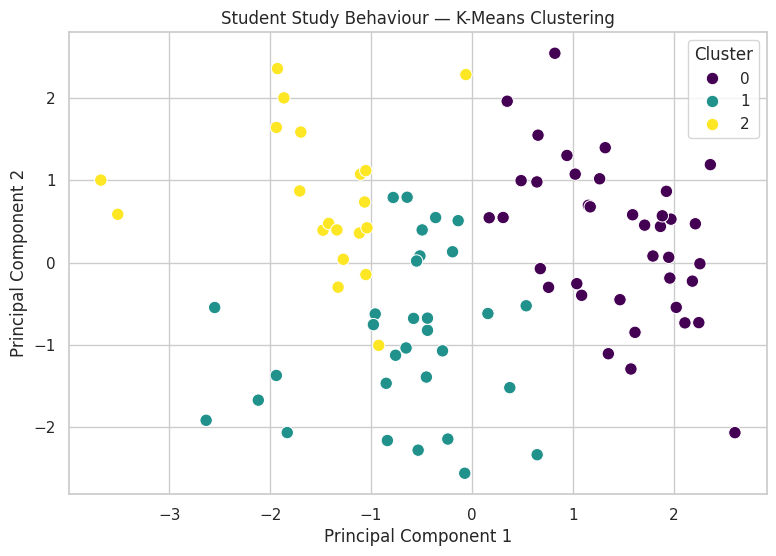

Variance explained by two components: 48.19 %


In [51]:
#10. Visualize the clusters
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=features["Cluster"],
    palette="viridis",
    s=80
)

plt.title("Student Study Behaviour — K-Means Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.show()

print(
    "Variance explained by two components:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)


Stage 6 — Library Occupancy Analysis


In [52]:
#Step 2 — Create an occupancy dataset in Colab
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Create occupancy data template

occupancy = pd.DataFrame(columns=[
    "Date",
    "Time",
    "Total_Seats",
    "Occupied_Seats"
])

occupancy.to_csv("library_occupancy_template.csv", index=False)

print("Occupancy template created!")

Occupancy template created!


In [53]:
from google.colab import files
files.download("library_occupancy_template.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [56]:
#Step 3 — Load the occupancy data
from google.colab import files
uploaded = files.upload()

Saving library_occupancy_template.csv to library_occupancy_template (1).csv


In [58]:
# Load the uploaded occupancy data
occupancy = pd.read_csv("library_occupancy_template (1).csv")

display(occupancy.head())

,Date,Time,Total_Seats,Occupied_Seats


In [59]:
print(occupancy.info())
print(occupancy.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 0 entries
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Date            0 non-null      object
 1   Time            0 non-null      object
 2   Total_Seats     0 non-null      object
 3   Occupied_Seats  0 non-null      object
dtypes: object(4)
memory usage: 132.0+ bytes
None
Date              0
Time              0
Total_Seats       0
Occupied_Seats    0
dtype: int64


In [60]:
#Step 4 — Calculate occupancy percentage
occupancy["Occupancy_Rate"] = (
    occupancy["Occupied_Seats"] /
    occupancy["Total_Seats"]
) * 100

display(occupancy)


,Date,Time,Total_Seats,Occupied_Seats,Occupancy_Rate


In [61]:
occupancy = pd.DataFrame(columns=[
    "Date",
    "Time",
    "Total_Seats",
    "Occupied_Seats"
])

In [62]:
occupancy = pd.DataFrame({
    "Date": ["20-11-2026"] * 5,
    "Time": ["09:00", "11:00", "13:00", "15:00", "17:00"],
    "Total_Seats": [200, 200, 200, 200, 200],
    "Occupied_Seats": [65, 110, 145, 170, 185]
})

occupancy["Occupancy_Rate"] = (
    occupancy["Occupied_Seats"] /
    occupancy["Total_Seats"]
) * 100

display(occupancy)

,Date,Time,Total_Seats,Occupied_Seats,Occupancy_Rate
0,20-11-2026,09:00,200,65,32.5
1,20-11-2026,11:00,200,110,55.0
2,20-11-2026,13:00,200,145,72.5
3,20-11-2026,15:00,200,170,85.0
4,20-11-2026,17:00,200,185,92.5


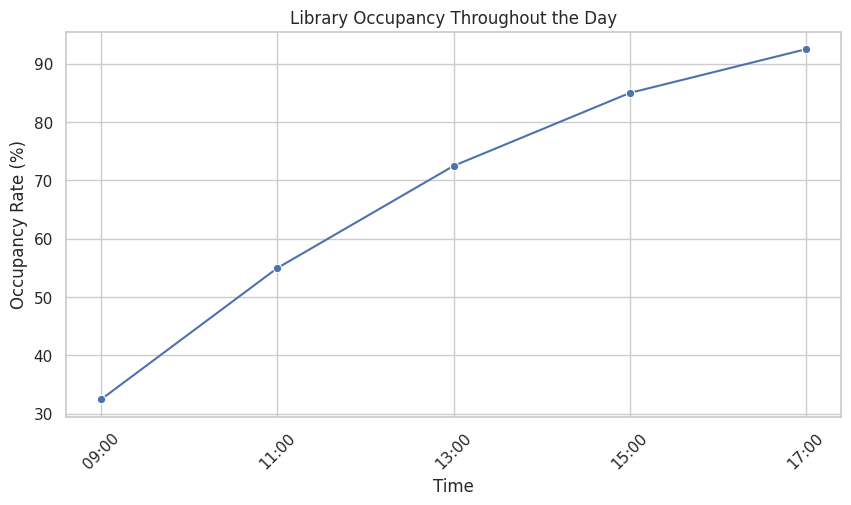

In [64]:
#Step 5 — Visualize occupancy throughout the day
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=occupancy,
    x="Time",
    y="Occupancy_Rate",
    marker="o"
)

plt.title("Library Occupancy Throughout the Day")
plt.xlabel("Time")
plt.ylabel("Occupancy Rate (%)")
plt.xticks(rotation=45)
plt.show()


In [67]:
#Step 6 — Identify peak occupancy
peak = occupancy.loc[
    occupancy["Occupancy_Rate"].idxmax()
]

print("Peak Occupancy Time:", peak["Time"])
print("Peak Occupancy Rate:", round(
    peak["Occupancy_Rate"], 2
), "%")

Peak Occupancy Time: 17:00
Peak Occupancy Rate: 92.5 %


In [68]:
#Step 7 — Save the results
occupancy.to_csv(
    "library_occupancy_analysis.csv",
    index=False
)